# Current contributors and practices

This notebook produces every number and figure of the *Current contributors and practices* subsection, following approach steps 1-3 of the assignment:
1. metrics to categorise contributors by involvement (frequent, newcomer, dormant), with thresholds justified by the data;
2. simple metrics covering the activities in the project;
3. process-oriented metrics, chosen based on what steps 1 and 2 show.

It needs the files written by `1_data_collection_filtering.ipynb` in `data/` and the cloned `repo.git`.

In [1]:
import re, subprocess
import pandas as pd
import matplotlib.pyplot as plt
import os
os.makedirs("figs", exist_ok=True)

In [2]:
# constants

start = pd.Timestamp("2025-01-01", tz="UTC")
end = pd.Timestamp("2026-01-01", tz="UTC")
repo_path = "repo.git"

frequent_months = 4      # frequent: active in >= 4 months of 2025 (justified below)
dormant_days = 365       # dormant: >= 1 year without contributions (justified below)
retention_days = 270     # newcomer retention window (our data ends in Oct 2026)

# plot style
blue, orange, aqua, yellow, ink, grey = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})

In [3]:
# load the output of notebook 1

commits = pd.read_csv("data/commits.csv", parse_dates=["author_date", "commit_date"])
prs = pd.read_csv("data/prs.csv", parse_dates=["merged_at"])
pr_commits = pd.read_csv("data/pr_commits.csv")
person_map = pd.read_csv("data/person_map.csv")
shared = set(pd.read_csv("data/shared_logins.csv").login)

pid = dict(zip(person_map.node, person_map.person_id))
bots = set(person_map[person_map.is_bot].node)

def git(*args):
    return subprocess.run(["git", "-C", repo_path, *args], capture_output=True,
                          text=True, encoding="utf-8", errors="replace").stdout

In [4]:
# one row per contribution: (person, date, type)
# a contribution = a merged PR authored (via the PR login) or a non-merge commit authored (via the email)

c = commits[~commits.is_merge].copy()
c["node"] = "email:" + c.author_email
c = c[~c.node.isin(bots)]
act_commits = pd.DataFrame({"person_id": c.node.map(pid), "date": c.commit_date, "type": "commit"})

p = prs.copy()
p["login"] = p.pr_login.str.lower()
p["node"] = "login:" + p.login
p = p[~p.node.isin(bots) & ~p.login.isin(shared)]
act_prs = pd.DataFrame({"person_id": p.node.map(pid), "date": p.merged_at, "type": "pr"})

act = pd.concat([act_commits, act_prs]).dropna()
act = act[act.person_id >= 0]
act["person_id"] = act.person_id.astype(int)
y = act[(act.date >= start) & (act.date < end)].copy()
y["month"] = y.date.dt.month
print(len(act), "contributions in total |", len(y), "in 2025 |", y.person_id.nunique(), "people active in 2025")

139806 contributions in total | 7066 in 2025 | 553 people active in 2025


## 1. Contributor categories

**Involvement metrics** per person (bots excluded, identities merged):
- *contributions* in 2025: merged PRs authored + non-merge commits authored (size of involvement)
- *active months*: months of 2025 with at least one contribution (regularity)
- *first contribution ever* (newcomers)
- *time since last contribution* (dormancy)

Limitation: all four only count merged code. Reviewing, triaging and helping others are invisible in git.

In [5]:
first = act.groupby("person_id").date.min()
last_before = act[act.date < start].groupby("person_id").date.max()

people = y.groupby("person_id").agg(contributions=("type", "size"), months=("month", "nunique"),
                                    prs=("type", lambda s: (s == "pr").sum()))
people["first_ever"] = first
people["last_before_2025"] = last_before
people.describe()

,contributions,months,prs
count,553.000000,553.000000,553.000000
mean,12.777577,2.575045,4.699819
std,32.802484,2.549913,11.983849
min,1.000000,1.000000,0.000000
25%,2.000000,1.000000,1.000000
50%,2.000000,2.000000,1.000000
75%,8.000000,3.000000,3.000000
max,447.000000,12.000000,156.000000


### Threshold for dormant: 365 days

How long do people normally pause? For every person, we take the gaps between consecutive days with a contribution (all history before 2025). If a gap of one year is extremely rare among normal pauses, then one year of silence means the person has stopped.

In [6]:
h = act[act.date < start].copy()
h["day"] = h.date.dt.floor("D")
d = h.drop_duplicates(["person_id", "day"]).sort_values(["person_id", "day"])
gaps = d.groupby("person_id").day.diff().dt.days.dropna()
print(len(gaps), "gaps")
gaps.quantile([0.5, 0.75, 0.9, 0.95, 0.99]).rename("days")

65250 gaps


0.50      3.00
0.75      9.00
0.90     35.00
0.95     81.00
0.99    359.02
Name: days, dtype: float64

The median gap is 3 days and 99% of gaps are shorter than 359 days, so 365 days without a contribution is not a normal pause: we call that person **dormant**.

### Threshold for frequent: at least 4 active months

In [7]:
months_dist = people.months.value_counts().sort_index()
print(months_dist.to_dict())

rows = []
for t in [2, 3, 4, 5, 6, 8]:
    s = people[people.months >= t]
    rows.append({"threshold (months)": t, "people": len(s), "share of people": round(len(s) / len(people), 3),
                 "share of contributions": round(s.contributions.sum() / people.contributions.sum(), 3)})
pd.DataFrame(rows)

{1: 274, 2: 122, 3: 45, 4: 28, 5: 19, 6: 13, 7: 12, 8: 9, 9: 1, 10: 15, 11: 9, 12: 6}


,threshold (months),people,share of people,share of contributions
0,2,279,0.505,0.920
1,3,157,0.284,0.846
2,4,112,0.203,0.790
3,5,84,0.152,0.728
4,6,65,0.118,0.675
5,8,40,0.072,0.537


Half of all people (274 of 553) were active in only one month. From 4 months on, each extra month adds few people: the 20% active in at least 4 months produce 79% of all contributions. Lower thresholds mainly add people with one or two small PRs, higher ones drop people who clearly carry the project, so we use **at least 4 active months** for frequent contributors.

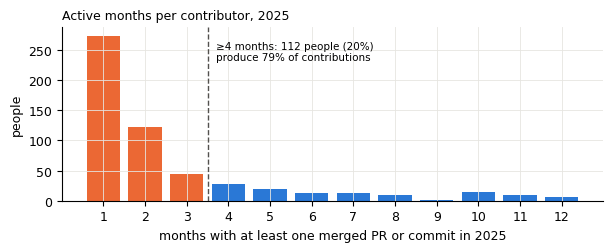

In [8]:
fig, ax = plt.subplots(figsize=(6.2, 2.6))
m = months_dist.reindex(range(1, 13), fill_value=0)
ax.bar(m.index, m.values, color=[orange if k < frequent_months else blue for k in m.index], width=0.8)
ax.axvline(frequent_months - 0.5, color=grey, lw=1, ls="--")
ax.text(frequent_months - 0.3, m.max() * 0.85, "≥4 months: 112 people (20%)\nproduce 79% of contributions", fontsize=7.5)
ax.set_xticks(range(1, 13))
ax.set_xlabel("months with at least one merged PR or commit in 2025")
ax.set_ylabel("people")
ax.set_title("Active months per contributor, 2025", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig("figs/active_months.pdf")
fig.savefig("figs/active_months.png", dpi=300)
plt.show()

### Categories

In [9]:
def category(r):
    if r.first_ever >= start:
        return "Newcomer"                                   # first contribution ever in 2025
    if r.months >= frequent_months:
        return "Frequent"
    if r.last_before_2025 < start - pd.Timedelta(days=dormant_days):
        return "Returning"                                  # back after >= 1 year of dormancy
    return "Occasional"

people["category"] = people.apply(category, axis=1)

# dormant: active in 2024, no contribution at all in 2025
active_2024 = set(act[(act.date >= start - pd.Timedelta(days=366)) & (act.date < start)].person_id)
dormant = active_2024 - set(people.index)

cat = people.groupby("category").agg(people=("months", "size"), contributions=("contributions", "sum"), prs=("prs", "sum"))
cat["share of contributions"] = (cat.contributions / cat.contributions.sum()).round(3)
cat["share of PRs"] = (cat.prs / cat.prs.sum()).round(3)
print("dormant (active in 2024, not in 2025):", len(dormant), "of", len(active_2024), f"= {len(dormant)/len(active_2024):.0%}")
cat.loc[["Frequent", "Occasional", "Returning", "Newcomer"]]

dormant (active in 2024, not in 2025): 346 of 535 = 65%


,people,contributions,prs,share of contributions,share of PRs
category,,,,,
Frequent,94,5015,1811,0.710,0.697
Occasional,105,512,207,0.072,0.080
Returning,62,216,86,0.031,0.033
Newcomer,292,1323,495,0.187,0.190


In [10]:
# how concentrated is the work? (how many people produce half / 80% of all contributions)

srt = people.contributions.sort_values(ascending=False).cumsum() / people.contributions.sum()
print("people for 50% of contributions:", (srt < 0.5).sum() + 1)
print("people for 80% of contributions:", (srt < 0.8).sum() + 1)
print("newcomers active in >= 4 months:", ((people.category == "Newcomer") & (people.months >= frequent_months)).sum())

labels = p.assign(pid=p.node.map(pid)).groupby("pid").pr_login.agg(lambda s: s.value_counts().index[0])
top = people.sort_values("contributions", ascending=False).head(10).copy()
top["login"] = top.index.map(labels)
top[["login", "contributions", "prs", "months"]]

people for 50% of contributions: 28
people for 80% of contributions: 106
newcomers active in >= 4 months: 18


,login,contributions,prs,months
person_id,,,,
4032,pohly,447,156,12
1525,carlory,213,100,12
4465,serathius,192,91,10
1353,BenTheElder,188,58,10
5314,yongruilin,188,47,8
1797,danwinship,163,43,11
2863,jpbetz,161,44,11
1909,dims,150,68,12
3710,natasha41575,130,44,11


### Roles: approvers and reviewers

Kubernetes defines roles in `OWNERS` files: *reviewers* review code in a directory, *approvers* give the final approval. Group names (aliases, e.g. `sig-node-approvers`) are defined in `OWNERS_ALIASES`. We read all of them as of the end of 2025.

In [11]:
snapshot = git("rev-list", "-1", "--before=2026-01-01T00:00:00Z", "master").strip()
owner_files = [f for f in git("ls-tree", "-r", "--name-only", snapshot).split("\n")
               if f == "OWNERS" or f.endswith("/OWNERS")]
print(len(owner_files), "OWNERS files")

def yaml_list(text, key):
    # read the list under 'key:' in an OWNERS file
    out, on = [], False
    for line in text.splitlines():
        s = line.split("#")[0].rstrip()
        if re.match(rf"^{key}:\s*$", s):
            on = True
            continue
        if on:
            m = re.match(r"^\s*-\s*([\w\-\.]+)", s)
            if m:
                out.append(m.group(1).lower())
            elif s.strip():
                on = False
    return out

aliases, current = {}, None
for line in git("show", f"{snapshot}:OWNERS_ALIASES").splitlines():
    s = line.split("#")[0].rstrip()
    m = re.match(r"^  ([\w\-]+):\s*$", s)
    if m:
        current = m.group(1)
        aliases[current] = []
    elif current and (m := re.match(r"^\s+-\s*([\w\-]+)", s)):
        aliases[current].append(m.group(1).lower())

approvers, reviewers, emeritus = set(), set(), set()
for f in owner_files:
    text = git("show", f"{snapshot}:{f}")
    for who in yaml_list(text, "approvers"):
        approvers |= set(aliases.get(who, [who]))
    for who in yaml_list(text, "reviewers"):
        reviewers |= set(aliases.get(who, [who]))
    emeritus |= set(yaml_list(text, "emeritus_approvers") + yaml_list(text, "emeritus_reviewers"))
for name, members in aliases.items():
    if name.endswith("approvers"):
        approvers |= set(members)
    elif name.endswith("reviewers"):
        reviewers |= set(members)

approvers = {a for a in approvers if "bot" not in a}
reviewers = {r for r in reviewers if "bot" not in r} - approvers
print("approvers:", len(approvers), "| reviewers (not approver):", len(reviewers), "| emeritus:", len(emeritus))

545 OWNERS files
approvers: 163 | reviewers (not approver): 53 | emeritus: 110


In [12]:
# which categories hold a role?

login_of = {}
for node, p_id in pid.items():
    if node.startswith("login:"):
        login_of.setdefault(p_id, set()).add(node[6:])

people["has_role"] = [bool(login_of.get(i, set()) & (approvers | reviewers)) for i in people.index]
people.groupby("category").has_role.agg(["sum", "size"]).rename(columns={"sum": "approver or reviewer", "size": "people"})

,approver or reviewer,people
category,,
Frequent,58,94
Newcomer,5,292
Occasional,22,105
Returning,11,62


## 2. Activity metrics

We track the activities per month. PRs opened and issues opened come from the interim report (GitHub search API); PRs merged, human commits and active contributors come from git, with bots excluded.
- **PRs opened**: contribution attempts.
- **PRs merged**: accepted work. Merged per opened shows whether attempts turn into accepted work.
- **Issues opened**: problem reports and feature requests from users.
- **Human commits**: code work by people (the interim count included 37% bot merge commits).
- **Active contributors**: people with at least one contribution, i.e. how many people carry the work.

Comments, reviews and the share of bot comments are not in git; they come from the GitHub API in `4_api_metrics.ipynb`.

In [13]:
# from the interim report notebook (k8s_activity_2025.csv)
interim = pd.DataFrame({
    "prs_opened":    [324, 401, 417, 290, 333, 407, 519, 282, 393, 506, 359, 338],
    "issues_opened": [163, 151, 194, 147, 140, 177, 181, 153, 135, 163, 139, 116]},
    index=range(1, 13))

p25 = prs[(prs.merged_at >= start) & (prs.merged_at < end)]
monthly = interim.copy()
monthly["prs_merged"] = p25.groupby(p25.merged_at.dt.month).size()
monthly["human_commits"] = y[y.type == "commit"].groupby("month").size()
monthly["active_contributors"] = y.groupby("month").person_id.nunique()
monthly["merged_per_opened"] = (monthly.prs_merged / monthly.prs_opened).round(2)
monthly.loc["total"] = [monthly.prs_opened.sum(), monthly.issues_opened.sum(), monthly.prs_merged.sum(),
                        monthly.human_commits.sum(), y.person_id.nunique(),
                        round(monthly.prs_merged.sum() / monthly.prs_opened.sum(), 2)]
monthly

,prs_opened,issues_opened,prs_merged,human_commits,active_contributors,merged_per_opened
1,324.0,163.0,175.0,267.0,104.0,0.54
2,401.0,151.0,189.0,340.0,107.0,0.47
3,417.0,194.0,330.0,622.0,137.0,0.79
4,290.0,147.0,134.0,175.0,92.0,0.46
5,333.0,140.0,199.0,341.0,103.0,0.60
6,407.0,177.0,210.0,345.0,120.0,0.52
7,519.0,181.0,405.0,659.0,158.0,0.78
8,282.0,153.0,130.0,231.0,110.0,0.46
9,393.0,135.0,239.0,368.0,125.0,0.61
10,506.0,163.0,289.0,555.0,140.0,0.57


About 57% as many PRs are merged as are opened. The ratio peaks in March (79%) and July (78%), the months that end with a code freeze, and drops to 43-47% in the months right after a release. Merged and opened PRs in a month are different PRs, so this is a throughput ratio, not an acceptance rate.

In [14]:
# the same over the years: active contributors, newcomers, and people going dormant

rows = []
for yr in range(2016, 2026):
    a, b = pd.Timestamp(f"{yr}-01-01", tz="UTC"), pd.Timestamp(f"{yr + 1}-01-01", tz="UTC")
    active = set(act[(act.date >= a) & (act.date < b)].person_id)
    previous = set(act[(act.date >= a - pd.Timedelta(days=366)) & (act.date < a)].person_id)
    rows.append({"year": yr, "active": len(active),
                 "newcomers": sum(1 for x in active if first[x] >= a),
                 "went_dormant": len(previous - active)})
flow = pd.DataFrame(rows).set_index("year")
flow

,active,newcomers,went_dormant
year,,,
2016,718,526,407
2017,862,583,457
2018,924,554,517
2019,986,605,591
2020,892,507,653
2021,824,433,560
2022,668,320,533
2023,586,284,422
2024,535,247,363


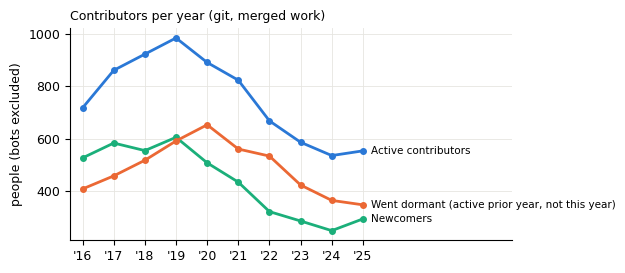

In [15]:
fig, ax = plt.subplots(figsize=(6.2, 2.8))
for col, key, lab in [(blue, "active", "Active contributors"), (aqua, "newcomers", "Newcomers"),
                      (orange, "went_dormant", "Went dormant (active prior year, not this year)")]:
    ax.plot(flow.index, flow[key], color=col, lw=2, marker="o", ms=4)
    ax.annotate(lab, (flow.index[-1], flow[key].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=7.5)
ax.set_xlim(2015.6, 2029.8)
ax.set_xticks(flow.index)
ax.set_xticklabels([f"'{y % 100:02d}" for y in flow.index])
ax.set_ylabel("people (bots excluded)")
ax.set_title("Contributors per year (git, merged work)", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig("figs/yearly_flow.pdf")
fig.savefig("figs/yearly_flow.png", dpi=300)
plt.show()

## 3. Process metrics

Steps 1 and 2 show a small core doing most of the work, a large group of newcomers that mostly stays for one month, and a contributor base that shrank since 2019. This raises process questions. The git-based ones are answered here; acceptance rate, time to first response, stale/bot closures and `/ok-to-test` waits need the API and are in `4_api_metrics.ipynb`.
1. **Do newcomers stay?** *Newcomer retention*: share of people whose first merged PR falls in a year and who get a second PR merged within 270 days.
2. **Are newcomers' PRs handled as well as others'?** *Lead time* (CHAOSS change request duration): days from the first commit of a PR to its merge, by author category.
3. **Are the roles filled by active people?** *Approver activity*: share of approvers who contributed in 2025.

In [16]:
# newcomer retention per cohort
# unit = a merged PR the person authored or has commits in (a PR with commits on several days counts once)

u1 = pr_commits.merge(commits[["sha", "author_email"]], on="sha")
u1["person_id"] = ("email:" + u1.author_email).map(pid)
u2 = pd.DataFrame({"person_id": ("login:" + prs.pr_login.str.lower()).map(pid), "pr_number": prs.pr_number})
units = pd.concat([u1[["person_id", "pr_number"]], u2]).dropna()
units = units[units.person_id >= 0].drop_duplicates()
units = units.merge(prs[["pr_number", "merged_at"]], on="pr_number").sort_values("merged_at")
first_pr = units.groupby("person_id").merged_at.min()

rows = []
for yr in range(2019, 2026):
    a, b = pd.Timestamp(f"{yr}-01-01", tz="UTC"), pd.Timestamp(f"{yr + 1}-01-01", tz="UTC")
    cohort = first_pr[(first_pr >= a) & (first_pr < b)]
    cohort = cohort[first.reindex(cohort.index) >= a]          # no earlier commit either
    second = units[units.person_id.isin(cohort.index)].groupby("person_id").merged_at.apply(
        lambda s: s.iloc[1] if len(s) > 1 else pd.NaT).reindex(cohort.index)
    days = (second - cohort).dt.total_seconds() / 86400
    rows.append({"cohort": yr, "newcomers": len(cohort), "retained": int((days <= retention_days).sum()),
                 "retention": round((days <= retention_days).mean(), 3),
                 "median_days_to_2nd_pr": round(days[days <= retention_days].median(), 1)})
retention = pd.DataFrame(rows).set_index("cohort")
print("average 2019-2023:", round(retention.loc[2019:2023, "retention"].mean(), 3))
retention

average 2019-2023: 0.383


,newcomers,retained,retention,median_days_to_2nd_pr
cohort,,,,
2019,581,224,0.386,17.2
2020,476,188,0.395,24.2
2021,397,160,0.403,25.6
2022,290,100,0.345,36.2
2023,258,99,0.384,23.5
2024,230,68,0.296,25.7
2025,259,78,0.301,28.7


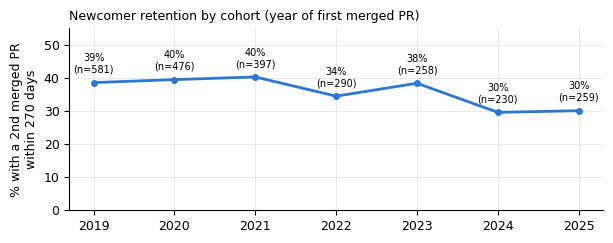

In [17]:
fig, ax = plt.subplots(figsize=(6.2, 2.5))
ax.plot(retention.index, retention.retention * 100, color=blue, lw=2, marker="o", ms=4)
for yr, r in retention.iterrows():
    ax.annotate(f"{r.retention:.0%}\n(n={int(r.newcomers)})", (yr, r.retention * 100),
                xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7)
ax.set_ylim(0, 55)
ax.set_ylabel("% with a 2nd merged PR\nwithin 270 days")
ax.set_xticks(retention.index)
ax.set_title("Newcomer retention by cohort (year of first merged PR)", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig("figs/retention.pdf")
fig.savefig("figs/retention.png", dpi=300)
plt.show()

In [18]:
# lead time: first commit of the PR -> merge, by category of the PR author

first_commit = pr_commits.merge(commits[["sha", "author_date"]], on="sha").groupby("pr_number").author_date.min()
lt = p25.copy()
lt["lead_days"] = (lt.merged_at - lt.pr_number.map(first_commit)).dt.total_seconds() / 86400
lt["category"] = ("login:" + lt.pr_login.str.lower()).map(pid).map(people.category)
lt = lt.dropna(subset=["lead_days", "category"])
lt = lt[lt.lead_days >= 0]
lt.groupby("category").lead_days.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1)

,count,mean,std,min,25%,50%,75%,90%,max
category,,,,,,,,,
Frequent,1811.0,26.3,75.4,0.0,0.8,5.0,22.9,64.3,1283.4
Newcomer,495.0,24.2,62.8,0.0,0.9,6.2,26.5,56.7,1042.8
Occasional,207.0,56.4,126.1,0.0,1.5,12.5,54.6,159.0,1344.9
Returning,86.0,28.5,61.4,0.1,0.7,5.8,27.0,64.7,417.1


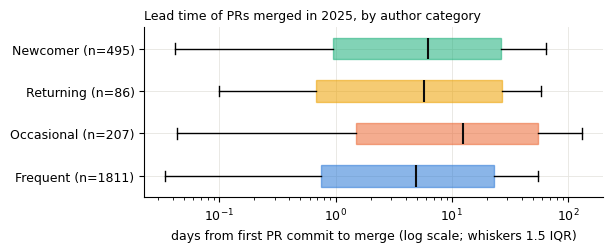

In [19]:
order = ["Frequent", "Occasional", "Returning", "Newcomer"]
fig, ax = plt.subplots(figsize=(6.2, 2.6))
data = [lt[lt.category == k].lead_days.clip(lower=0.01) for k in order]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=[f"{k} (n={len(d)})" for k, d in zip(order, data)],
                showfliers=False, patch_artist=True, widths=0.5, medianprops={"color": ink, "lw": 1.5})
for patch, col in zip(bp["boxes"], [blue, orange, yellow, aqua]):
    patch.set_facecolor(col); patch.set_alpha(0.55); patch.set_edgecolor(col)
ax.set_xscale("log")
ax.set_xlabel("days from first PR commit to merge (log scale; whiskers 1.5 IQR)")
ax.set_title("Lead time of PRs merged in 2025, by author category", fontsize=9, loc="left")
fig.tight_layout()
fig.savefig("figs/lead_time.pdf")
fig.savefig("figs/lead_time.png", dpi=300)
plt.show()

In [20]:
# approver activity: did the people listed as approvers contribute in 2025?

active_ids = set(people.index)
linked = {a: pid.get("login:" + a) for a in approvers}
with_identity = {a for a, i in linked.items() if i is not None and i >= 0}
active_approvers = {a for a in with_identity if linked[a] in active_ids}
print("approvers:", len(approvers), "| with a git identity:", len(with_identity),
      "| contributed in 2025:", len(active_approvers), f"({len(active_approvers)/len(with_identity):.0%})")

sig = []
for name, members in aliases.items():
    if name.endswith("approvers") and name.startswith("sig-") and not name.endswith("api-approvers"):
        members = {m for m in members if "bot" not in m}
        sig.append({"alias": name, "approvers": len(members),
                    "contributed_2025": sum(1 for m in members if pid.get("login:" + m) in active_ids)})
pd.DataFrame(sig).sort_values("approvers", ascending=False).head(10)

approvers: 163 | with a git identity: 150 | contributed in 2025: 68 (45%)


,alias,approvers,contributed_2025
18,sig-docs-approvers,10,2
11,sig-node-approvers,9,2
17,sig-contributor-experience-approvers,8,2
15,sig-instrumentation-approvers,7,4
12,sig-node-cri-approvers,6,3
10,sig-storage-approvers,6,3
13,sig-network-approvers,5,3
14,sig-apps-approvers,5,3
19,sig-scalability-approvers,5,4
7,sig-auth-node-isolation-approvers,4,3


Approvers mostly *review*, which git does not show, so this is a lower bound on their activity. It still shows that many listed approvers did not contribute any code in 2025.

## Save for notebook 4 (API metrics)

In [21]:
people[["category"]].to_csv("data/people_2025.csv")
first.rename("first_contribution").to_csv("data/first_contribution.csv")
pd.Series(sorted(approvers), name="login").to_csv("data/approvers.csv", index=False)
print("saved")

saved
